# Thoughts

Just check for nearest points in the vicinity and then also check their orientations (of the track segment starts) in relation to the track segment start / end point of search. Then, probably also check for edge cases and maybe a fall-back / validation for which we would need to figure out the actual crossing segments (as positions) though...

In [1]:
import matplotlib.pyplot as plt
import numpy as np
from scipy.interpolate import splprep, splev
from scipy.ndimage import binary_erosion, find_objects, label

from mcap.reader import make_reader
from mcap_ros2.decoder import DecoderFactory

from numpy.typing import NDArray
from typing import Tuple, Optional, List

from dataclasses import dataclass, field
from matplotlib.path import Path
from matplotlib.patches import Rectangle

In [2]:
# Additional structs (maybe go over the class again and add a few more for things like segments to make the code
# more streamlined and easier to understand)

@dataclass
class TrackSegment:
    """An undirected road separator with an arbitrary reference point order."""

    center_points: NDArray[np.float64]
    start_crossing_id: Optional[int] = None
    end_crossing_id: Optional[int] = None

    def get_start(self) -> NDArray[np.float64]:
        return np.asarray(self.center_points[0], dtype=float)[:2]

    def get_end(self) -> NDArray[np.float64]:
        return np.asarray(self.center_points[-1], dtype=float)[:2]

    @staticmethod
    def get_tangent(points: NDArray) -> NDArray[np.float64]:
        """Unit direction for up to three points, in array order.

        For three equally parameterized samples, their linear-regression
        slope is (last - first) / 2; normalization removes the factor.
        """
        points = np.asarray(points, dtype=float)[:, :2]
        if len(points) < 2:
            return np.zeros(2)

        tangent = points[-1] - points[0]
        tangent_length = np.linalg.norm(tangent)
        if tangent_length == 0:
            return np.zeros(2)
        return tangent / tangent_length

    def get_start_orientation(self) -> NDArray[np.float64]:
        return self.get_tangent(self.center_points[:3])

    def get_end_orientation(self) -> NDArray[np.float64]:
        return self.get_tangent(self.center_points[-3:])


@dataclass
class Lane:
    """A directed lane; center_points follow its driving direction.

    follows_track_direction describes its direction relative to the parent
    track's reference order. That order need not have a global orientation.
    """

    lane_id: int
    track_segment_index: int
    follows_track_direction: bool
    center_points: NDArray[np.float64]
    start_crossing_id: Optional[int] = None
    end_crossing_id: Optional[int] = None
    next_lane_ids: List[int] = field(default_factory=list)
    connection_points: List[NDArray[np.float64]] = field(default_factory=list)

    lane_length: Optional[float] = None
    connection_lengths: List[float] = field(default_factory=list)


    def get_start(self) -> NDArray[np.float64]:
        return self.center_points[0]

    def get_end(self) -> NDArray[np.float64]:
        return self.center_points[-1]

    def get_start_orientation(self) -> NDArray[np.float64]:
        return TrackSegment.get_tangent(self.center_points[:3])

    def get_end_orientation(self) -> NDArray[np.float64]:
        return TrackSegment.get_tangent(self.center_points[-3:])


# (original endpoint, index in fitted_track_separation_lines, is_start)
# The point index within that line is therefore 0 for start and -1 for end.
TrackBound = Tuple[NDArray[np.float64], int, bool]


@dataclass
class Crossing:
    crossing_id: int
    bounds: Tuple[float, float, float, float]  # min_x, min_y, max_x, max_y
    center_point: NDArray[np.float64]  # Mean of the original component cells
    track_bounds: List[TrackBound] = field(default_factory=list)

In [3]:
def get_distance(x: NDArray, y: NDArray) -> float:
    return np.sqrt(np.sum(np.square(x - y)))


def average_points(points: NDArray, num_points: int) -> NDArray:
    """Loop over a list of points and average `num_points` of them. Returns a list of averaged points."""

    max_index = int(len(points) / num_points)
    averaged_points = np.zeros((max_index, 3))

    for i in range(max_index):
        average = np.mean(points[i * num_points: (i + 1) * num_points], axis=0)
        averaged_points[i, :] = average

    return averaged_points


def extract_point(point, strip_z_component: bool) -> NDArray:
    """Transform a given point from a ros2 vector object to a NumPy array and return it."""

    vec = np.zeros(3)
    vec[0] = point.x
    vec[1] = point.y

    if not strip_z_component:
        vec[2] = point.z

    return vec

# Signed polygon area trick (negative means clockwise).
def is_clockwise(points: NDArray) -> bool:
    signed_area = 0.0

    for i in range(len(points)):
        current_point = points[i]
        next_point = points[(i + 1) % len(points)]

        signed_area += current_point[0] * next_point[1] - next_point[0] * current_point[1]

    return signed_area < 0

In [4]:
def remove_near_duplicates_and_overlays(points: NDArray) -> NDArray:
    """Removes consecutive near duplicates and cuts of the end of the array in case of overlap with the start.
    The function assumes previous averaging as else the condition detection is highly unreliable due to small
    positional errors of the points."""

    # Compute distances between consecutive original points.
    distances = np.array([get_distance(points[i + 1], points[i])for i in range(len(points) - 1)])

    # Now the average spread and some rather arbitrary bound
    avg_spread = np.mean(distances)
    minimum_spread = avg_spread / 1.5

    # Keep the first point, then accumulate distance until keeping another.
    keep_mask = np.zeros(len(points), dtype=bool)
    keep_mask[0] = True

    accumulated_distance = 0.0

    for i in range(1, len(points)):
        accumulated_distance += distances[i - 1]

        if accumulated_distance >= minimum_spread:
            keep_mask[i] = True
            accumulated_distance = 0.0

    points = points[keep_mask]

    # Inspect the end of the recording for start/end overlap.
    first_point = points[0]
    last_distance = get_distance(points[-1], first_point)

    if last_distance > avg_spread:
        closest_index = len(points) - 1
        closest_distance = last_distance
        previous_distance = last_distance
        consecutive_increases = 0

        # Exclude index 0: its distance to itself is always zero.
        for i in range(len(points) - 2, 0, -1):
            current_distance = get_distance(points[i], first_point)

            if current_distance < closest_distance:
                closest_distance = current_distance
                closest_index = i

            if current_distance > previous_distance:
                consecutive_increases += 1
            else:
                consecutive_increases = 0

            if consecutive_increases >= 2:
                points = points[:closest_index]
                break

            previous_distance = current_distance

    return points

In [5]:
# This can very likely be simplified (by a lot). But since it works, this is currently not a priority.
def identify_corners(points: NDArray, sample_spacing: float = 0.1,
                     window_distance: float = 0.20, minimum_corner_angle: float = 40.0) -> Tuple[NDArray, NDArray]:
    """Identify corner positions on a closed curve.

    Distances are in metres and the angle threshold is in degrees.
    Returns corner positions in curve order.
    """

    def estimate_heading(window_points: NDArray) -> float:
        middle_index = len(window_points) // 2

        first_average = np.mean(window_points[:middle_index], axis=0)
        second_average = np.mean(window_points[middle_index:], axis=0)

        direction = second_average - first_average

        return np.degrees(np.arctan2(direction[1], direction[0]))

    # Include the closing segment when computing distances.
    if np.array_equal(points[0], points[-1]):
        closed_points = points
    else:
        closed_points = np.vstack((points, points[0]))

    distances = np.linalg.norm(
        np.diff(closed_points[:, :2], axis=0),
        axis=1,
    )
    cumulative_distances = np.concatenate(([0.0], np.cumsum(distances)))
    total_distance = cumulative_distances[-1]

    # Resample at approximately equal physical distances.
    number_samples = int(np.ceil(total_distance / sample_spacing))

    sample_distances = np.linspace(
        0.0, total_distance, number_samples, endpoint=False
    )

    resampled_points = np.zeros((number_samples, points.shape[1]))

    for coordinate in range(points.shape[1]):
        resampled_points[:, coordinate] = np.interp(
            sample_distances,
            cumulative_distances,
            closed_points[:, coordinate],
        )

    actual_spacing = total_distance / number_samples
    window_size = int(round(window_distance / actual_spacing))

    # Repetition allows windows to wrap around either end of the curve.
    extended_points = np.vstack((
        resampled_points,
        resampled_points,
        resampled_points,
    ))

    turn_angles = np.zeros(number_samples)

    for i in range(number_samples):
        center_index = number_samples + i

        before_window = extended_points[
            center_index - window_size:center_index
        ]
        after_window = extended_points[
            center_index:center_index + window_size
        ]

        incoming_heading = estimate_heading(before_window)
        outgoing_heading = estimate_heading(after_window)

        angle_difference = abs(outgoing_heading - incoming_heading)

        if angle_difference > 180.0:
            angle_difference = 360.0 - angle_difference

        turn_angles[i] = angle_difference

    # Find strong local maxima.
    candidate_indices = []

    for i in range(number_samples):
        previous_angle = turn_angles[i - 1]
        next_angle = turn_angles[(i + 1) % number_samples]
        current_angle = turn_angles[i]

        if (
            current_angle > minimum_corner_angle
            and current_angle >= previous_angle
            and current_angle > next_angle
        ):
            candidate_indices.append(i)

    # Prefer the strongest candidate when several describe one corner.
    candidate_indices.sort(
        key=lambda index: turn_angles[index],
        reverse=True,
    )

    selected_indices = []

    for candidate_index in candidate_indices:
        too_close = False

        for selected_index in selected_indices:
            separation = abs(
                sample_distances[candidate_index]
                - sample_distances[selected_index]
            )
            separation = min(separation, total_distance - separation)

            if separation < window_distance:
                too_close = True
                break

        if not too_close:
            selected_indices.append(candidate_index)

    selected_indices = np.array(sorted(selected_indices), dtype=int)

    return resampled_points, selected_indices

In [6]:
def unit_normal_at_point(points: NDArray, point_index: int, clockwise: bool, is_outer: bool) -> NDArray:
    """Return the unit normal pointing toward the road."""

    closed = np.array_equal(points[0], points[-1])

    if closed:
        points = points[:-1]
        point_index = point_index % len(points)

        previous_point = points[(point_index - 1) % len(points)]
        next_point = points[(point_index + 1) % len(points)]
    else:
        previous_point = points[max(point_index - 1, 0)]
        next_point = points[min(point_index + 1, len(points) - 1)]

    tangent = next_point[:2] - previous_point[:2]
    tangent_length = np.linalg.norm(tangent)

    if tangent_length == 0:
        return np.zeros(2)

    tangent = tangent / tangent_length
    normal = np.array([-tangent[1], tangent[0]])

    if clockwise:
        normal = -normal

    if not is_outer:
        normal = -normal

    return normal


def normal_line_intersection(point: NDArray, scaled_normal: NDArray, line_start: NDArray, line_end: NDArray) -> Optional[NDArray]:
    """Intersect a finite normal with one boundary edge. Returns a 2D point."""

    point = point[:2]
    normal = scaled_normal[:2]

    line_direction = line_end[:2] - line_start[:2]
    offset = line_start[:2] - point

    denominator = normal[0] * line_direction[1] - normal[1] * line_direction[0]

    # Parallel or collinear.
    parallel_bound = 1e-2
    if abs(denominator) < parallel_bound:  #1e-12:
        return None

    normal_fraction = (offset[0] * line_direction[1] - offset[1] * line_direction[0]) / denominator

    line_fraction = (offset[0] * normal[1] - offset[1] * normal[0]) / denominator

    if (0.0 < normal_fraction <= 1.0) and (0.0 <= line_fraction <= 1.0):
        return point + normal_fraction * normal

    return None

In [7]:
def fit_and_sample_spline(
        points: NDArray,
        number_samples: int = 100,
        rms_tolerance: float = 0.005,
        closed: bool = False,
    ) -> NDArray:
        """Fit a smoothing spline and return sampled 2D points."""

        points = np.asarray(points, dtype=float)[:, :2]

        if len(points) < 2:
            return points.copy()

        # Express the smoothing budget through an RMS fitting tolerance.
        smoothing_budget = len(points) * rms_tolerance**2
        spline_degree = min(3, len(points) - 1)

        spline, parameters = splprep(
            points.T,
            k=spline_degree,
            s=smoothing_budget,
            per=closed,
        )

        sample_parameters = np.linspace(0.0, 1.0, number_samples)
        sampled_x, sampled_y = splev(sample_parameters, spline)

        return np.column_stack((sampled_x, sampled_y))

In [8]:
class MapConstructor:
    def __init__(self, channel_topic: str = "tf"):
        # Initial data / overwritten after averaging
        self.outer: Optional[NDArray] = None
        self.inner: List[NDArray] = []

        # Track width (assumed essentially uniform everywhere)
        self.track_width: Optional[float] = None

        # Lists of point sequences describing distinct curve segments (separated by corners)
        self.outer_segments: List[NDArray]
        self.inner_segments: List[List[NDArray]] = []

        # Information for tangent direction of all closed curves
        self.outer_clockwise: bool
        self.inner_clockwise: List[bool]

        # Very nested representations of the intersection correspondences for each point from a given sequence
        # For one curve, we store: For each segment (if intersection found) -> current index (in segment we iterate
        # over), flag if outer (true = 1, false = 0), Other curve index, other segment index, the two indices of
        # that other segment that create the line that the scaled normal intersects. This creates a tuple:
        # (current_index, outer_flag, other_curve_index, other_segment_index, index_1, index_2)
        self.outer_curve_correspondences: List[NDArray] = []
        self.inner_curve_correspondences: List[NDArray] = []

        # Storing the 'cleaned up' / more efficient and compacted track segment pair data
        self.track_segment_maps = []

        # Store the track separation lines (as points)
        self.track_separation_lines = []

        # Store the fitted separation lines
        self.fitted_track_separation_lines = []

        # # Testing variable (pre full loop)
        self.results: List[List] = []

        # Crossing detection variables (maybe some can go in a refactoring pass, but for now...)
        self.raster_origin = None
        self.raster_resolution = None
        self.crossing_mask = None

        # Small mode / channel picker (+ verifier)
        if channel_topic == "tf":
            self.channel_topic = "/tf"
        elif channel_topic == "odometry":
            self.channel_topic = "/mapping_tool/odometry"
        else:
            raise ValueError("channel_topic must be 'tf' or 'odometry'")

    def load_ros_bag(self, path: str, measurement_type: str, strip_z_component: bool = True) -> None:
        """Load a ros bag file, extract the data and store it. `measurement_type` is 'inner' or 'outer'.
        'inner' can be multiple measurements and will be appended. 'outer' can only be one and will be set or replaced."""

        with open(path, 'rb') as f:
            reader = make_reader(f, decoder_factories=[DecoderFactory()])

            points = []

            for i, (schema, channel, message, msg) in enumerate(
            reader.iter_decoded_messages(topics=[self.channel_topic])):
                if channel.topic == "/tf":
                    position = msg.transforms[-1].transform.translation
                else:
                    position = msg.pose.pose.position

                points.append(extract_point(position, strip_z_component))

        points = np.array(points)

        if measurement_type == "outer":
            self.outer = points
        elif measurement_type == "inner":
            self.inner.append(points)
        else:
            raise ValueError("measurement_type must be 'outer' or 'inner'")

        return None

    def build_averages(self, num_points: int) -> None:
        # Once for outer
        if self.outer is not None:
            self.outer = average_points(self.outer, num_points)

        # Then loop over inner
        for i, points in enumerate(self.inner):
            self.inner[i] = average_points(points, num_points)

        return None

    # Some of these functions should probably rather be split, such that they are modular and can do a specific and
    # more general task. Then we have an additional function that should then be called on a class instance to
    # compute the properties for all relevant elements. I.e., get_tangents() -> get_tangents_for_consecutive_segment().

    # Also, we still need to add the data validations and pre-processing functions. Validation should probably take
    # no parameter, while preprocessing should likely allow for a few 'customizations'.

    def preprocess(self) -> None:
        """Should be called after all curves have been added. Currently written out as one long function but should
         eventually probably be split into parts that can then be called here."""

        # 1. Remove consecutive (near) duplicates and handle the 'closed curve assumption' and apply start / end overlap correction.
        # First do it for outer, then for inner. The logic should stay the same though
        if self.outer is not None:
            self.outer = remove_near_duplicates_and_overlays(self.outer)

            # Compute orientations (before splitting into segments)
            self.outer_clockwise = is_clockwise(self.outer)

        for i in range(len(self.inner)):
            self.inner[i] = remove_near_duplicates_and_overlays(self.inner[i])

            # Compute orientations (before splitting into segments)
            self.inner_clockwise = [is_clockwise(curve) for curve in self.inner]

        return None

# """Loop over a line measurement and identify (actual) corner positions. For now maybe focus on 90 degrees
#         but should also work in general for all angles not too close to 180 degrees. Returns a list of points"""

    def split_points_into_consecutive_segments(self, points: NDArray) -> List[NDArray]:
        """Extract points that describe lines between identified corner points. Returns a list of point sequences."""

        # The general idea is that we want to loop over each curve that has corner points and then split these points into
        # segments — separated by corner points. For this, the first and last parts need to be combined to one segment (since
        # they are between two corners, if there are any)

        # Then, to ensure consistency, each segment should have (if there are) the corner points at the end. This ensures same
        # starting and end points which might be useful for later fitting. Also, the new corner points might be very close to existing
        # points. To have no issues with gradients, we will replace these close-to-corner-points by the corner points. And, this
        # is kind of a blessing in disguise, but if the points are very close, and we have our preprocessing function so we can use this to identify the corner points (via small distance)... However, I am unsure if this is always guaranteed to be the case.

        resampled_points, corner_indices = identify_corners(points)

        # With no corners, keep the complete curve as one closed segment.
        if len(corner_indices) == 0:
            return [np.vstack((resampled_points, resampled_points[0]))]

        segments = []

        for i in range(len(corner_indices)):
            start_index = corner_indices[i]
            end_index = corner_indices[(i + 1) % len(corner_indices)]

            if end_index > start_index:
                segment = resampled_points[start_index:end_index + 1].copy()
            else:
                # Wrap from the last corner through the recording start.
                segment = np.vstack((
                    resampled_points[start_index:],
                    resampled_points[:end_index + 1],
                ))

            segments.append(segment)

        return segments

    def split_curves_into_segments(self) -> None:
        """Here we just call split_points_into_consecutive_segments() for the outer and the inner curves."""
        if self.outer is not None:
            self.outer_segments = self.split_points_into_consecutive_segments(self.outer)

        for curve in self.inner:
            self.inner_segments.append(self.split_points_into_consecutive_segments(curve))

        pass

    def get_tangents_for_consecutive_segment(self, num_adjacent: int) -> NDArray:
        """Get the tangents at each point (estimated from 2n + 1 points, width n (num_adjacent) = 1 as default)."""
        pass

    def identify_consecutive_track_segments(self):
        """Loop over the consecutive segments and identify pairs of segments (or / and actually only sequences of these
        pairs) that bound consecutive track segments."""

        # Very nested representations of the intersection correspondences for each point from a given sequence
        # For one curve, we store: For each segment (if intersection found) -> current segment, current index (in
        # segment we iterate over), flag if outer (true = 1, false = 0), Other curve index, other segment index, the
        # two indices of that other segment that create the line that the scaled normal intersects. This creates a
        # tuple: (curve, current_segment, current_index, outer_flag, other_curve_index, other_segment_index, index_1, index_2)

        # First do it for the outer curve
        for s, segment in enumerate(self.outer_segments):
            for i in range(len(segment)):
                normal = unit_normal_at_point(
                    points=segment,
                    point_index=i,
                    clockwise=self.outer_clockwise,
                    is_outer=True,
                )

                # The 1.1 is a somewhat arbitrary factor to 'counter' map imperfections.
                scaled_normal = 1.1 * self.track_width * normal

                # Search the other segments of the outer boundary (Fix after big-map-trial)
                for k, other_segment in enumerate(self.outer_segments):
                    if k == s:
                        continue

                    for l in range(len(other_segment) - 1):
                        intersection = normal_line_intersection(
                            segment[i],
                            scaled_normal,
                            other_segment[l],
                            other_segment[l + 1],
                        )

                        if intersection is not None:
                            result = [s, i, 1, 0, k, l, l + 1]
                            self.outer_curve_correspondences.append(result)

                # Now we have to loop over the other segments (here only all other inner)
                for j, other_curve_segments in enumerate(self.inner_segments):
                    for k, other_segment in enumerate(other_curve_segments):
                        for l in range(len(other_segment) - 1):
                            intersection = normal_line_intersection(
                                segment[i],
                                scaled_normal,
                                other_segment[l],
                                other_segment[l + 1],
                            )

                            if intersection is not None:
                                # The intersection then lies between the points of other_segment at indices l and l + 1.
                                result = [s, i, 0, j, k, l, l + 1]

                                self.outer_curve_correspondences.append(result)

        # Now essentially the same thing (with one additional iteration for multiple inner curves)
        for c, curve_segments in enumerate(self.inner_segments):
            for s, segment in enumerate(curve_segments):
                for i in range(len(segment)):
                    normal = unit_normal_at_point(
                        points=segment,
                        point_index=i,
                        clockwise=self.inner_clockwise[c],
                        is_outer=False,
                    )

                    # The 1.1 allows for map imperfections.
                    scaled_normal = 1.1 * self.track_width * normal

                    closest_distance = float("inf")
                    best_result = None

                    # First search the outer segments.
                    for k, other_segment in enumerate(self.outer_segments):
                        for l in range(len(other_segment) - 1):
                            intersection = normal_line_intersection(
                                segment[i],
                                scaled_normal,
                                other_segment[l],
                                other_segment[l + 1],
                            )

                            if intersection is not None:
                                distance = np.linalg.norm(intersection - segment[i, :2])

                                if distance < closest_distance:
                                    closest_distance = distance
                                    best_result = [c, s, i, 1, 0, k, l, l + 1]

                    # Then search the remaining inner curves.
                    for j, other_curve_segments in enumerate(self.inner_segments):
                        if j == c:
                            continue

                        for k, other_segment in enumerate(other_curve_segments):
                            for l in range(len(other_segment) - 1):
                                intersection = normal_line_intersection(
                                    segment[i],
                                    scaled_normal,
                                    other_segment[l],
                                    other_segment[l + 1],
                                )

                                if intersection is not None:
                                    distance = np.linalg.norm(intersection - segment[i, :2])

                                    if distance < closest_distance:
                                        closest_distance = distance
                                        best_result = [c, s, i, 0, j, k, l, l + 1]

                    # Store at most one correspondence for this source point.
                    if best_result is not None:
                        self.inner_curve_correspondences.append(best_result)

    def clean_track_segment_maps(self) -> None:
        """Here we should clean up the (probably) highly redundant data of the identified consecutive track segments.
        We essentially want to go over the data and return a tuple:
        For outer: List of inner curves (Optional(List(List of segments (start index, stop index))) — or something
        like this. And then a similar structure for the outer curves..."""
        pass

    def join_short_corner_runs(self) -> None:
        """Join tiny target-corner transitions along the same source segment."""

        maximum_corner_points = 2
        maximum_missed_points = 2

        def can_join(first_map, second_map):
            if first_map["source"] != second_map["source"]:
                return False

            first_start, first_stop = first_map["source_range"]
            second_start, second_stop = second_map["source_range"]
            gap = second_start - first_stop

            if gap < -maximum_corner_points or gap > maximum_missed_points:
                return False

            if first_map["target"] == second_map["target"]:
                return True

            # Different boundaries should remain separate.
            if first_map["target"][:2] != second_map["target"][:2]:
                return False

            if (
                first_stop - first_start > maximum_corner_points
                and second_stop - second_start > maximum_corner_points
            ):
                return False

            outer_flag, curve_index, first_segment = first_map["target"]
            second_segment = second_map["target"][2]

            if outer_flag:
                segments = self.outer_segments
            else:
                segments = self.inner_segments[curve_index]

            first_range = first_map["target_range"]
            second_range = second_map["target_range"]

            forward_corner = (
                (first_segment + 1) % len(segments) == second_segment
                and len(segments[first_segment]) - first_range[1]
                    <= maximum_corner_points
                and second_range[0] <= maximum_corner_points
            )

            backward_corner = (
                (second_segment + 1) % len(segments) == first_segment
                and first_range[0] <= maximum_corner_points
                and len(segments[second_segment]) - second_range[1]
                    <= maximum_corner_points
            )

            return forward_corner or backward_corner

        joined_maps = []

        for segment_map in self.track_segment_maps:
            joined_maps.append(segment_map)

            while len(joined_maps) >= 2:
                first_map, second_map = joined_maps[-2:]

                if not can_join(first_map, second_map):
                    break

                first_length = (
                    first_map["source_range"][1]
                    - first_map["source_range"][0]
                )
                second_length = (
                    second_map["source_range"][1]
                    - second_map["source_range"][0]
                )

                main_map = (
                    first_map if first_length >= second_length else second_map
                )
                merged_map = main_map.copy()

                merged_map["source_range"] = (
                    min(first_map["source_range"][0],
                        second_map["source_range"][0]),
                    max(first_map["source_range"][1],
                        second_map["source_range"][1]),
                )

                sections = (
                    first_map.get("target_sections", [first_map])
                    + second_map.get("target_sections", [second_map])
                )
                merged_map["target_sections"] = sections

                main_ranges = [
                    section["target_range"]
                    for section in sections
                    if section["target"] == merged_map["target"]
                ]

                merged_map["target_range"] = (
                    min(start for start, stop in main_ranges),
                    max(stop for start, stop in main_ranges),
                )

                joined_maps[-2:] = [merged_map]

        self.track_segment_maps = joined_maps

    def clean_track_segment_maps(self) -> None:
        """Group correspondences, join short corner runs, and handle seams."""

        self.track_segment_maps = []
        maximum_missed_points = 2
        correspondences = []

        for result in self.outer_curve_correspondences:
            source = (1, 0, result[0])
            target = tuple(result[2:5])

            correspondences.append((
                source, result[1], target, result[5], result[6]
            ))

        for result in self.inner_curve_correspondences:
            source = (0, result[0], result[1])
            target = tuple(result[3:6])

            correspondences.append((
                source, result[2], target, result[6], result[7]
            ))

        correspondences.sort(key=lambda entry: (entry[0], entry[1]))

        current_source = None
        current_target = None

        start_index = 0
        previous_index = 0
        minimum_target_index = 0
        maximum_target_index = 0

        def save_current_run():
            self.track_segment_maps.append({
                "source": current_source,
                "target": current_target,
                "source_range": (start_index, previous_index + 1),
                "target_range": (
                    minimum_target_index,
                    maximum_target_index + 1,
                ),
            })

        for correspondence in correspondences:
            (
                source,
                point_index,
                target,
                first_target_index,
                second_target_index,
            ) = correspondence

            missed_points = point_index - previous_index - 1

            extend_current_run = (
                source == current_source
                and target == current_target
                and missed_points <= maximum_missed_points
            )

            if extend_current_run:
                minimum_target_index = min(
                    minimum_target_index, first_target_index
                )
                maximum_target_index = max(
                    maximum_target_index, second_target_index
                )
            else:
                if current_source is not None:
                    save_current_run()

                current_source = source
                current_target = target
                start_index = point_index

                minimum_target_index = first_target_index
                maximum_target_index = second_target_index

            previous_index = point_index

        if current_source is not None:
            save_current_run()

        # Join short corner transitions before creating wrapped ranges.
        self.join_short_corner_runs()

        # Collect maps belonging to each source segment.
        maps_by_source = {}

        for segment_map in self.track_segment_maps:
            source = segment_map["source"]

            if source not in maps_by_source:
                maps_by_source[source] = []

            maps_by_source[source].append(segment_map)

        for source, source_maps in maps_by_source.items():
            if len(source_maps) < 2:
                continue

            outer_flag, curve_index, segment_index = source

            if outer_flag:
                points = self.outer_segments[segment_index]
            else:
                points = self.inner_segments[curve_index][segment_index]

            # Only join across the seam of a closed source segment.
            if not np.array_equal(points[0], points[-1]):
                continue

            source_maps.sort(
                key=lambda entry: entry["source_range"][0]
            )

            first_map = source_maps[0]
            last_map = source_maps[-1]

            if first_map["target"] != last_map["target"]:
                continue

            first_start, first_stop = first_map["source_range"]
            last_start, last_stop = last_map["source_range"]

            missed_points = first_start + len(points) - last_stop

            if missed_points > maximum_missed_points:
                continue

            # Preserve every contributing target section.
            last_map["target_sections"] = (
                last_map.get("target_sections", [last_map.copy()])
                + first_map.get("target_sections", [first_map.copy()])
            )

            last_map["source_range"] = (last_start, first_stop)

            last_map["target_range"] = (
                min(
                    first_map["target_range"][0],
                    last_map["target_range"][0],
                ),
                max(
                    first_map["target_range"][1],
                    last_map["target_range"][1],
                ),
            )

            self.track_segment_maps.remove(first_map)

    def estimate_track_width(self, width: Optional[float] = None) -> None:
        """Get the width of the track (both directions, i.e. width between inner and outer). Assumes equal track width
        everywhere. If width is provided, this is used instead of running the algorithm to determine the width."""
        if width is not None:
            self.track_width = width
            return None

        # Handle algorithmic part here
        pass


    def get_segment_track_separation(self) -> None:
        self.track_separation_lines = []
        self.fitted_track_separation_lines = []

        kept_maps = []
        used_ranges = set()

        for segment_map in self.track_segment_maps:
            outer_flag, curve_index, segment_index = segment_map["source"]
            target_outer_flag, target_curve_index, target_segment_index = segment_map["target"]

            # Keep outer → inner, discard inner → outer.
            if not outer_flag and target_outer_flag:
                continue

            # Keep only one direction between inner curves.
            if not outer_flag and not target_outer_flag:
                if curve_index > target_curve_index:
                    continue

            # Keep only one direction between outer segments.
            if outer_flag and target_outer_flag:
                if segment_index > target_segment_index:
                    continue

            source_range_key = (
                tuple(segment_map["source"]),
                tuple(segment_map["source_range"]),
            )
            target_range_key = (
                tuple(segment_map["target"]),
                tuple(segment_map["target_range"]),
            )

            if (
                source_range_key in used_ranges
                or target_range_key in used_ranges
            ):
                continue

            if outer_flag:
                points = self.outer_segments[segment_index]
                clockwise = self.outer_clockwise
            else:
                points = self.inner_segments[curve_index][segment_index]
                clockwise = self.inner_clockwise[curve_index]

            start_index, stop_index = segment_map["source_range"]
            closed = np.array_equal(points[0], points[-1])

            if start_index > stop_index:
                point_indices = (
                    list(range(start_index, len(points) - 1))
                    + list(range(stop_index))
                )
            else:
                point_indices = range(start_index, stop_index)

            middle_points = []

            for point_index in point_indices:
                normal = unit_normal_at_point(
                    points=points,
                    point_index=point_index,
                    clockwise=clockwise,
                    is_outer=bool(outer_flag),
                )

                middle_point = (
                    points[point_index, :2]
                    + 0.5 * self.track_width * normal
                )

                middle_points.append(middle_point.tolist())

            kept_maps.append(segment_map)
            self.track_separation_lines.append(middle_points)

            used_ranges.add(source_range_key)
            used_ranges.add(target_range_key)

        self.track_segment_maps = kept_maps

    def merge_reverse_middle_points(self) -> None:
        merged_maps = []
        merged_middle_points = []
        mapping_indices = {}

        for segment_map, middle_points in zip(
            self.track_segment_maps,
            self.track_separation_lines,
        ):
            # Group by boundary-segment identities, ignoring index ranges.
            source = tuple(segment_map["source"])
            target = tuple(segment_map["target"])

            # Same key for A → B and B → A.
            mapping_key = tuple(sorted((source, target)))

            if mapping_key not in mapping_indices:
                mapping_indices[mapping_key] = len(merged_maps)
                merged_maps.append(segment_map)
                merged_middle_points.append([])

            index = mapping_indices[mapping_key]
            merged_middle_points[index].extend(middle_points)

        self.track_segment_maps = merged_maps
        self.track_separation_lines = merged_middle_points

    def fit_lines_with_splines(self) -> None:
        self.fitted_track_separation_lines = []

        for middle_points in self.track_separation_lines:
            fitted_points = fit_and_sample_spline(
                np.array(middle_points)
            )
            self.fitted_track_separation_lines.append(fitted_points)

    def get_track_segment_bound_normals(self):
        """Compute the normals for the bound of the start and end of each continuous track segment. As a convention, they point
        along the direction of driving of the right-side track (double check id this convention is enough).

        In other words, this should compute the tangents of the middle track segments with the convention, that they always
        point in the direction of driving for the right-side segment.

        Then (either in this function or another), we can use this information to get a mapping of which segments connect to a
        given one. This can then also be extended to map start / end points of different segments, also for the different directions.
        This can then ultimately be used to generate a directed graph of connections for navigation. """

        # Is it sufficient for the normal computation using the stated convention, to just pick the first elements in the order
        # that they appear in the array and to revert the order of the last?

        pass

    def get_crossing_bounds(self):
        """Get bounds of the segments that are not part of any track segment, i.e. spaces where there is more than one
        way to keep on driving."""
        pass


    def build_crossing_mask(self, resolution: float = 0.1) -> None:
        """Rasterize the outer and inner boundaries into a boolean mask."""

        curves = [self.outer] + self.inner
        all_points = np.vstack([curve[:, :2] for curve in curves])

        minimum_x = np.min(all_points[:, 0])
        maximum_x = np.max(all_points[:, 0])
        minimum_y = np.min(all_points[:, 1])
        maximum_y = np.max(all_points[:, 1])

        number_columns = int(np.ceil((maximum_x - minimum_x) / resolution))
        number_rows = int(np.ceil((maximum_y - minimum_y) / resolution))

        self.raster_origin = (minimum_x, minimum_y)
        self.raster_resolution = resolution

        self.crossing_mask = np.zeros(
            (number_rows, number_columns),
            dtype=bool,
        )

        # Test the center of each raster cell.
        x_coordinates = minimum_x + (
            np.arange(number_columns) + 0.5
        ) * resolution

        y_coordinates = minimum_y + (
            np.arange(number_rows) + 0.5
        ) * resolution

        x_grid, y_grid = np.meshgrid(x_coordinates, y_coordinates)
        grid_points = np.column_stack((x_grid.ravel(), y_grid.ravel()))

        # Fill the area inside the outer boundary.
        outer_boundary = Path(self.outer[:, :2])
        inside_outer = outer_boundary.contains_points(grid_points)
        inside_outer = inside_outer.reshape(self.crossing_mask.shape)

        self.crossing_mask[inside_outer] = True

        # Remove the areas inside the inner boundaries.
        for curve in self.inner:
            inner_boundary = Path(curve[:, :2])
            inside_inner = inner_boundary.contains_points(grid_points)
            inside_inner = inside_inner.reshape(self.crossing_mask.shape)

            self.crossing_mask[inside_inner] = False


    def build_track_mask(self) -> None:
        """Rasterize all known road corridors into one boolean mask."""

        number_rows, number_columns = self.crossing_mask.shape
        minimum_x, minimum_y = self.raster_origin
        resolution = self.raster_resolution

        self.track_mask = np.zeros_like(self.crossing_mask, dtype=bool)

        # Recreate the same grid-cell centers.
        x_coordinates = minimum_x + (
            np.arange(number_columns) + 0.5
        ) * resolution

        y_coordinates = minimum_y + (
            np.arange(number_rows) + 0.5
        ) * resolution

        x_grid, y_grid = np.meshgrid(x_coordinates, y_coordinates)
        grid_points = np.column_stack((x_grid.ravel(), y_grid.ravel()))

        for fitted_points in self.fitted_track_separation_lines:
            middle_points = np.asarray(fitted_points)[:, :2]

            if len(middle_points) < 2:
                continue

            # Estimate unit tangents along the middle line.
            tangents = np.gradient(middle_points, axis=0)
            tangent_lengths = np.linalg.norm(
                tangents, axis=1, keepdims=True
            )

            tangents = tangents / np.where(
                tangent_lengths == 0, 1.0, tangent_lengths
            )

            # Either normal orientation works for a symmetric road band.
            normals = np.column_stack((
                -tangents[:, 1],
                tangents[:, 0],
            ))

            left_edge = middle_points + 0.5 * self.track_width * normals
            right_edge = middle_points - 0.5 * self.track_width * normals

            # Reversing the second edge produces a polygon with flat ends.
            road_polygon = np.vstack((left_edge, right_edge[::-1]))

            road_boundary = Path(road_polygon)
            segment_mask = road_boundary.contains_points(grid_points)
            segment_mask = segment_mask.reshape(self.track_mask.shape)

            self.track_mask |= segment_mask


    def identify_crossings(self) -> None:
        """Keep components containing a filled q x q square.

        The square test filters components without shrinking accepted ones.
        crossing_mask stays unchanged; crossing_labels stores accepted IDs.
        """
        resolution = self.raster_resolution
        minimum_x, minimum_y = self.raster_origin
        square_size = max(1, int(np.ceil(self.track_width / (2 * resolution))))
        square = np.ones((square_size, square_size), dtype=bool)

        component_labels, _ = label(self.crossing_mask)
        component_slices = find_objects(component_labels)

        self.crossing_labels = np.zeros_like(component_labels)
        self.crossings = []
        self.unmatched_track_bounds = []

        for component_id, component_slice in enumerate(component_slices, start=1):
            if component_slice is None:
                continue

            component_mask = component_labels[component_slice] == component_id
            if min(component_mask.shape) < square_size:
                continue
            if not np.any(binary_erosion(component_mask, structure=square)):
                continue

            crossing_id = len(self.crossings) + 1
            local_labels = self.crossing_labels[component_slice]
            local_labels[component_mask] = crossing_id

            row_slice, column_slice = component_slice
            bounds = (
                minimum_x + column_slice.start * resolution,
                minimum_y + row_slice.start * resolution,
                minimum_x + column_slice.stop * resolution,
                minimum_y + row_slice.stop * resolution,
            )

            local_rows, local_columns = np.nonzero(component_mask)
            center_point = np.array([
                minimum_x + (column_slice.start + local_columns.mean() + 0.5) * resolution,
                minimum_y + (row_slice.start + local_rows.mean() + 0.5) * resolution,
            ])

            self.crossings.append(Crossing(crossing_id, bounds, center_point))


    def match_track_bounds_to_crossings(
        self,
        forward_distance: Optional[float] = None,
        backward_distance: Optional[float] = None,
    ) -> None:
        """Associate middle-line starts/ends with nearby crossing components.

        Search along the direction pointing out of the track. Distances are
        in metres; defaults are one track width forward and a quarter back.
        These are road middle-line matches, not yet directed lane matches.
        """
        if forward_distance is None:
            forward_distance = self.track_width
        if backward_distance is None:
            backward_distance = self.track_width / 4
        if forward_distance < 0 or backward_distance < 0:
            raise ValueError("Search distances must be non-negative.")

        resolution = self.raster_resolution
        minimum_x, minimum_y = self.raster_origin
        number_rows, number_columns = self.crossing_labels.shape

        # Half-cell steps limit the chance of skipping a cell along the ray.
        search_step = resolution / 2
        search_distances = np.concatenate((
            [0.0, forward_distance, -backward_distance],
            np.arange(search_step, forward_distance, search_step),
            -np.arange(search_step, backward_distance, search_step),
        ))
        # Closest sample first; prefer forward over backward in a tie.
        search_distances = sorted(
            np.unique(search_distances),
            key=lambda distance: (abs(distance), distance < 0),
        )

        for crossing in self.crossings:
            crossing.track_bounds.clear()
        self.unmatched_track_bounds = []

        for middle_index, middle_points in enumerate(self.fitted_track_separation_lines):
            middle_points = np.asarray(middle_points, dtype=float)[:, :2]
            if len(middle_points) < 2:
                continue
            # An explicitly closed middle line has no road entrances.
            if np.allclose(middle_points[0], middle_points[-1], rtol=0, atol=1e-9):
                continue

            for is_start in (True, False):
                if is_start:
                    point = middle_points[0].copy()
                    outward_direction = -TrackSegment.get_tangent(middle_points[:3])
                else:
                    point = middle_points[-1].copy()
                    outward_direction = TrackSegment.get_tangent(middle_points[-3:])

                track_bound = (point, middle_index, is_start)
                matched_crossing_id = 0

                if np.linalg.norm(outward_direction) > 0:
                    for distance in search_distances:
                        search_point = point + distance * outward_direction
                        column = int(np.floor((search_point[0] - minimum_x) / resolution))
                        row = int(np.floor((search_point[1] - minimum_y) / resolution))

                        if not (0 <= row < number_rows and 0 <= column < number_columns):
                            continue

                        crossing_id = int(self.crossing_labels[row, column])
                        if crossing_id != 0:
                            matched_crossing_id = crossing_id
                            break

                if matched_crossing_id:
                    self.crossings[matched_crossing_id - 1].track_bounds.append(track_bound)
                else:
                    self.unmatched_track_bounds.append(track_bound)


    def create_lanes(self) -> None:
        """Construct two directed lanes per track, assuming right-hand traffic.

        Run after match_track_bounds_to_crossings(). Each lane is offset by
        one quarter of the full road width from its separator. Track indices
        retain their meaning in fitted_track_separation_lines.
        """
        endpoint_crossings = {}
        for crossing in self.crossings:
            for point, middle_index, is_start in crossing.track_bounds:
                endpoint_crossings[(middle_index, is_start)] = crossing.crossing_id

        self.track_segments = []
        self.lanes = []

        for track_index, middle_points in enumerate(self.fitted_track_separation_lines):
            points = np.asarray(middle_points, dtype=float)[:, :2].copy()
            track_segment = TrackSegment(
                center_points=points,
                start_crossing_id=endpoint_crossings.get((track_index, True)),
                end_crossing_id=endpoint_crossings.get((track_index, False)),
            )
            self.track_segments.append(track_segment)
            if len(points) < 2:
                continue

            # Use centered differences inside, one-sided differences at ends.
            if np.allclose(points[0], points[-1], rtol=0, atol=1e-9):
                # For explicitly closed arrays, use neighbors across the seam.
                unique_points = points[:-1]
                tangents = np.roll(unique_points, -1, axis=0) - np.roll(unique_points, 1, axis=0)
                tangents = np.vstack((tangents, tangents[0]))
            else:
                tangents = np.gradient(points, axis=0)

            tangent_lengths = np.linalg.norm(tangents, axis=1, keepdims=True)
            tangents = tangents / np.where(tangent_lengths == 0, 1.0, tangent_lengths)
            right_normals = np.column_stack((tangents[:, 1], -tangents[:, 0]))
            offsets = self.track_width / 4 * right_normals

            # Right of the reference direction: drive in reference order.
            forward_lane = Lane(
                lane_id=len(self.lanes),
                track_segment_index=track_index,
                follows_track_direction=True,
                center_points=points + offsets,
                start_crossing_id=track_segment.start_crossing_id,
                end_crossing_id=track_segment.end_crossing_id,
            )
            self.lanes.append(forward_lane)

            # Left of the reference direction: drive in reversed order.
            reverse_lane = Lane(
                lane_id=len(self.lanes),
                track_segment_index=track_index,
                follows_track_direction=False,
                center_points=(points - offsets)[::-1].copy(),
                start_crossing_id=track_segment.end_crossing_id,
                end_crossing_id=track_segment.start_crossing_id,
            )
            self.lanes.append(reverse_lane)

    def connect_lanes(self, num_points: int = 30, control_point_factor: float = 0.4) -> None:
        """Connect lanes at shared crossings using cubic Bezier curves.

        next_lane_ids[k] and connection_points[k] describe the same connection.
        Connector points include both endpoints and follow driving direction.
        """
        if num_points < 2:
            raise ValueError("num_points must be at least 2.")
        if control_point_factor <= 0:
            raise ValueError("control_point_factor must be positive.")

        parameters = np.linspace(0.0, 1.0, num_points)[:, None]

        # Clear previous connections so repeated calls do not create duplicates.
        for lane in self.lanes:
            lane.next_lane_ids.clear()
            lane.connection_points.clear()

        for lane in self.lanes:
            if lane.end_crossing_id is None:
                continue

            for next_lane in self.lanes:
                if next_lane.start_crossing_id != lane.end_crossing_id:
                    continue

                # Exclude returning along the same track.
                if next_lane.track_segment_index == lane.track_segment_index:
                    continue

                start_point = lane.get_end()
                end_point = next_lane.get_start()

                start_direction = lane.get_end_orientation()
                end_direction = next_lane.get_start_orientation()

                distance = np.linalg.norm(end_point - start_point)
                control_distance = control_point_factor * distance

                first_control_point = (
                    start_point + control_distance * start_direction
                )
                second_control_point = (
                    end_point - control_distance * end_direction
                )

                connection_points = (
                    (1 - parameters) ** 3 * start_point
                    + 3 * (1 - parameters) ** 2
                    * parameters * first_control_point
                    + 3 * (1 - parameters)
                    * parameters ** 2 * second_control_point
                    + parameters ** 3 * end_point
                )

                lane.next_lane_ids.append(next_lane.lane_id)
                lane.connection_points.append(connection_points)


    # Some plotting functions


    def plot_crossing_components(self) -> None:
        """Show accepted cells, approximate boxes, and matched track bounds.

        Matching endpoint colors indicate crossing membership; black crosses
        are unmatched. Endpoint labels show middle-line index and S/E.
        Arrows point out of the road, not along a lane's driving direction.
        """
        figure, axis = plt.subplots()
        resolution = self.raster_resolution
        minimum_x, minimum_y = self.raster_origin

        if self.outer is not None:
            axis.plot(self.outer[:, 0], self.outer[:, 1], color="0.7", linewidth=1)
        for curve in self.inner:
            axis.plot(curve[:, 0], curve[:, 1], color="0.7", linewidth=1)
        for middle_points in self.fitted_track_separation_lines:
            middle_points = np.asarray(middle_points)
            if len(middle_points) > 0:
                axis.plot(middle_points[:, 0], middle_points[:, 1], color="0.4", linewidth=1)

        for crossing in self.crossings:
            color = plt.get_cmap("tab20")((crossing.crossing_id - 1) % 20)
            rows, columns = np.nonzero(self.crossing_labels == crossing.crossing_id)
            x_values = minimum_x + (columns + 0.5) * resolution
            y_values = minimum_y + (rows + 0.5) * resolution
            axis.scatter(x_values, y_values, color=color, marker="s", s=8, alpha=0.5)

            min_x, min_y, max_x, max_y = crossing.bounds
            axis.add_patch(Rectangle(
                (min_x, min_y), max_x - min_x, max_y - min_y,
                fill=False, edgecolor=color, linestyle="--",
            ))
            # axis.text(*crossing.center_point, f"C{crossing.crossing_id}", color="black")

            for point, middle_index, is_start in crossing.track_bounds:
                middle_points = np.asarray(self.fitted_track_separation_lines[middle_index])
                if is_start:
                    direction = -TrackSegment.get_tangent(middle_points[:3])
                else:
                    direction = TrackSegment.get_tangent(middle_points[-3:])
                    arrow_end = point + self.track_width / 3 * direction

                axis.scatter(*point, color=color, edgecolors="black", s=20, zorder=5)
                # axis.annotate(
                #     f"{middle_index}:{'S' if is_start else 'E'}",
                #     xy=point, xytext=(5, 5), textcoords="offset points", fontsize=8,
                # )
                # axis.annotate(
                #     "", xy=arrow_end, xytext=point,
                #     arrowprops=dict(arrowstyle="->", color=color, linewidth=2),
                # )

        # for point, middle_index, is_start in self.unmatched_track_bounds:
        #     axis.scatter(*point, color="black", marker="x", s=40, zorder=5)
        #     axis.annotate(
        #         f"{middle_index}:{'S' if is_start else 'E'}",
        #         xy=point, xytext=(5, 5), textcoords="offset points", fontsize=8,
        #     )

        axis.set_aspect("equal", adjustable="box")
        axis.set_xlabel("x [m]")
        axis.set_ylabel("y [m]")
        plt.savefig("crossings_zoomed.png", dpi=500)
        plt.show()

    def plot_lanes(self) -> None:
        """Plot lanes, endpoint markers, driving arrows, and dotted connectors."""
        figure, axis = plt.subplots()

        if self.outer is not None:
            axis.plot(self.outer[:, 0], self.outer[:, 1], color="0.7", linewidth=1)
        for curve in self.inner:
            axis.plot(curve[:, 0], curve[:, 1], color="0.7", linewidth=1)
        for track_segment in self.track_segments:
            points = track_segment.center_points
            if len(points) > 0:
                axis.plot(points[:, 0], points[:, 1], color="0.5", linestyle="--", linewidth=0.8)

        for lane in self.lanes:
            points = lane.center_points
            color = "tab:blue" if lane.follows_track_direction else "tab:orange"
            axis.plot(points[:, 0], points[:, 1], color=color, linewidth=1.5)
            for connection_points in lane.connection_points:
                axis.plot(
                    connection_points[:, 0], connection_points[:, 1],
                    color=color, linestyle=":", linewidth=1.5, alpha=0.8,
                )
            axis.scatter(*lane.get_start(), color=color, s=15, zorder=5)
            axis.scatter(*lane.get_end(), color=color, marker="x", s=20, zorder=5)

            middle_index = len(points) // 2
            nearby_points = points[max(0, middle_index - 1):min(len(points), middle_index + 2)]
            direction = TrackSegment.get_tangent(nearby_points)
            arrow_start = points[middle_index]
            arrow_end = arrow_start + self.track_width / 3 * direction
            axis.annotate(
                "", xy=arrow_end, xytext=arrow_start,
                arrowprops=dict(arrowstyle="->", color=color, linewidth=2),
            )

        axis.plot([], [], color="tab:blue", label="Along track order")
        axis.plot([], [], color="tab:orange", label="Against track order")
        axis.legend()
        axis.set_aspect("equal", adjustable="box")
        axis.set_xlabel("x [m]")
        axis.set_ylabel("y [m]")
        plt.show()

    def plot_crossing_mask(self, mask_type: str = "crossings") -> None:
        if mask_type == "tracks":
            mask = self.track_mask
            title = "Known road corridors"
        elif mask_type == "crossings":
            mask = self.crossing_mask
            title = "Current crossing mask"
        else:
            raise ValueError("mask_type must be 'tracks' or 'crossings'")

        number_rows, number_columns = mask.shape
        minimum_x, minimum_y = self.raster_origin
        resolution = self.raster_resolution

        maximum_x = minimum_x + number_columns * resolution
        maximum_y = minimum_y + number_rows * resolution

        plt.figure()

        plt.imshow(
            mask,
            origin="lower",
            extent=(minimum_x, maximum_x, minimum_y, maximum_y),
            cmap="gray",
            vmin=0,
            vmax=1,
            interpolation="nearest",
        )

        plt.title(title)
        plt.xlabel("x (m)")
        plt.ylabel("y (m)")
        plt.gca().set_aspect("equal", adjustable="box")
        plt.show()


    def plot_curves(self):
        if self.outer is not None:
            plt.scatter(self.outer[:,0], self.outer[:,1], s=1)

            resampled_points, corner_indices = identify_corners(self.outer)
            corner_points = resampled_points[corner_indices]

            plt.scatter(
                corner_points[:, 0],
                corner_points[:, 1],
                marker="x",
                color="red",
            )

        for curves in self.inner:
            plt.scatter(curves[:,0], curves[:,1], s=1)
            corner_points, indices = identify_corners(curves)
            corner_points = corner_points[indices]
            plt.scatter(corner_points[:,0], corner_points[:,1], marker='x', color='red')

        # Set this to enforce equal proportions for x and y
        plt.gca().set_aspect("equal", adjustable="box")

        # plt.xlim(1.7, 4.3)
        # plt.ylim(-0.5, 1.2)

        plt.show()

    def plot_segments(self) -> None:
        if self.outer is not None:
            for segment in self.outer_segments:
                plt.scatter(segment[:,0], segment[:,1], s=1)

        for curve_segments in self.inner_segments:
            for segment in curve_segments:
                plt.scatter(segment[:,0], segment[:,1], s=1)

        for result in self.results:
            idx_outer = result[0]
            idx_inner = result[1]
            plt.scatter(self.outer_segments[0][idx_outer][0], self.outer_segments[0][idx_outer][1], s=1, color='green')
            plt.scatter(self.inner_segments[0][0][idx_inner][0], self.inner_segments[0][0][idx_inner][1], s=1, color='green')

        # plt.scatter(self.expected_opposite_point[0], self.expected_opposite_point[1], marker='x', color='blue')

        plt.gca().set_aspect("equal", adjustable="box")

        plt.savefig("small_map_trial_run_fixed.png", dpi=300)
        plt.show()

    def plot_correspondences(self) -> None:
        plt.figure()

        print(len(self.track_segment_maps))

        # Show complete boundaries, including unmatched sections.
        for segment in self.outer_segments:
            plt.scatter(
                segment[:, 0],
                segment[:, 1],
                s=1,
                color="gray",
                zorder=0,
            )

        for curve_segments in self.inner_segments:
            for segment in curve_segments:
                plt.scatter(
                    segment[:, 0],
                    segment[:, 1],
                    s=1,
                    color="gray",
                    zorder=0,
                )

        for i, segment_map in enumerate(self.track_segment_maps):
            color = plt.cm.tab20(i % 20)

            sections = [("source", segment_map)]

            for target_section in segment_map.get(
                "target_sections", [segment_map]
            ):
                sections.append(("target", target_section))

            # Plot the source and all contributing target sections.
            for side, section in sections:
                outer_flag, curve_index, segment_index = section[side]

                if outer_flag:
                    points = self.outer_segments[segment_index]
                else:
                    points = self.inner_segments[curve_index][segment_index]

                start_index, stop_index = section[f"{side}_range"]

                if start_index > stop_index:
                    points = np.vstack((
                        points[start_index:-1],
                        points[:stop_index],
                    ))
                else:
                    points = points[start_index:stop_index]

                if side == "source":
                    source_points = points[:, :2]

                plt.scatter(
                    points[:, 0],
                    points[:, 1],
                    s=1,
                    color=color,
                )

            middle_points = np.array(self.track_separation_lines[i])

            # Mark both ends of the middle-point sequence.
            plt.scatter(
                middle_points[[0, -1], 0],
                middle_points[[0, -1], 1],
                marker="x",
                color="purple",
            )

            opposite_points = 2.0 * middle_points - source_points

            source_lane = np.vstack((
                source_points,
                middle_points[::-1],
            ))

            opposite_lane = np.vstack((
                middle_points,
                opposite_points[::-1],
            ))

            for lane_points, lane_color in (
                (source_lane, "tab:blue"),
                (opposite_lane, "tab:orange"),
            ):
                plt.fill(
                    lane_points[:, 0],
                    lane_points[:, 1],
                    color=lane_color,
                    alpha=0.15,
                    zorder=0,
                )

            # Add driving-direction arrows.
            middle_index = len(middle_points) // 2

            road_normal = (
                middle_points[middle_index]
                - source_points[middle_index]
            )
            normal_length = np.linalg.norm(road_normal)

            if normal_length > 0:
                driving_direction = np.array([
                    road_normal[1],
                    -road_normal[0],
                ]) / normal_length

                source_lane_position = (
                    source_points[middle_index]
                    + middle_points[middle_index]
                ) / 2.0

                opposite_lane_position = (
                    middle_points[middle_index]
                    + opposite_points[middle_index]
                ) / 2.0

                arrow_length = 0.3 * self.track_width

                for position, direction, lane_color in (
                    (
                        source_lane_position,
                        driving_direction,
                        "tab:blue",
                    ),
                    (
                        opposite_lane_position,
                        -driving_direction,
                        "tab:orange",
                    ),
                ):
                    plt.annotate(
                        "",
                        xy=position + arrow_length * direction,
                        xytext=position,
                        arrowprops=dict(
                            arrowstyle="->",
                            color=lane_color,
                            lw=2,
                        ),
                    )

            plt.scatter(
                middle_points[:, 0],
                middle_points[:, 1],
                color=color,
                s=1,
            )

            line = np.array(self.fitted_track_separation_lines[i])

            plt.plot(
                line[:, 0],
                line[:, 1],
                ls="--",
                color="black",
                lw=1,
            )

        plt.gca().set_aspect("equal", adjustable="box")
        plt.savefig("small_map_with_crossing_tangents.png", dpi=300)
        plt.show()

In [9]:
mc = MapConstructor('odometry')

map_types = ["small_provided", "small_own", "big"]
map_type = map_types[0]

if map_type == "small_provided":
    outer_path = "../data/Maps/outer.mcap"
    inner_path_1 = "../data/Maps/inner1.mcap"
    inner_path_2 = "../data/Maps/inner2.mcap"
elif map_type == "small_own":
    outer_path = "../data/Maps/own_outer_0.mcap"
    inner_path_1 = "../data/Maps/own_inner_10.mcap"
    inner_path_2 = "../data/Maps/own_inner_20.mcap"
elif map_type == "big":
    outer_path = "../data/Maps/sim_freicar_2/outer/outer.mcap"
    inner_path_1 = "../data/Maps/sim_freicar_2/inner1/inner1.mcap"
    inner_path_2 = "../data/Maps/sim_freicar_2/inner2/inner2.mcap"
    inner_path_3 = "../data/Maps/sim_freicar_2/inner3/inner3.mcap"
    inner_path_4 = "../data/Maps/sim_freicar_2/inner4/inner4.mcap"
    inner_path_5 = "../data/Maps/sim_freicar_2/inner5/inner5.mcap"
    inner_path_6 = "../data/Maps/sim_freicar_2/inner6/inner6.mcap"
    inner_path_7 = "../data/Maps/sim_freicar_2/inner7/inner7.mcap"
    inner_path_8 = "../data/Maps/sim_freicar_2/inner8/inner8.mcap"
    inner_path_9 = "../data/Maps/sim_freicar_2/inner9/inner9.mcap"
else:
    print("Double check map type")


mc.load_ros_bag(outer_path, "outer")
mc.load_ros_bag(inner_path_1, "inner")
mc.load_ros_bag(inner_path_2, "inner")

if map_type == "big":
    mc.load_ros_bag(inner_path_3, "inner")
    mc.load_ros_bag(inner_path_4, "inner")
    mc.load_ros_bag(inner_path_5, "inner")
    mc.load_ros_bag(inner_path_6, "inner")
    mc.load_ros_bag(inner_path_7, "inner")
    mc.load_ros_bag(inner_path_8, "inner")
    mc.load_ros_bag(inner_path_9, "inner")

mc.build_averages(50)

In [10]:
mc.preprocess()

In [11]:
# mc.build_crossing_mask(resolution=0.1)
# mc.plot_crossing_mask()

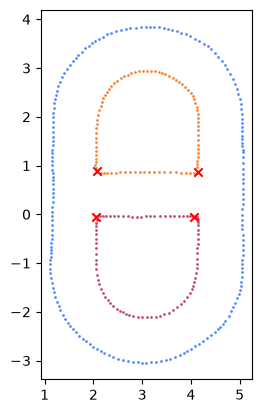

In [12]:
mc.plot_curves()

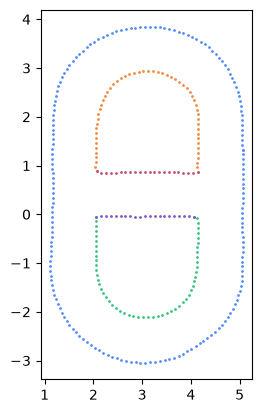

In [13]:
mc.split_curves_into_segments()

mc.estimate_track_width(0.92)
mc.identify_consecutive_track_segments()

mc.plot_segments()

3


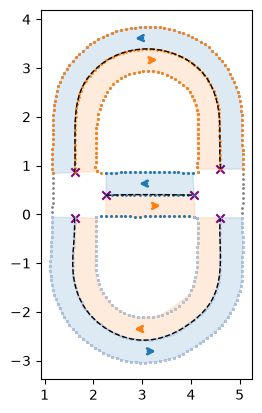

In [14]:
mc.clean_track_segment_maps()
mc.get_segment_track_separation()
mc.fit_lines_with_splines()

mc.plot_correspondences()

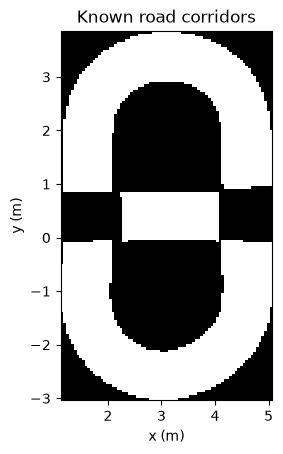

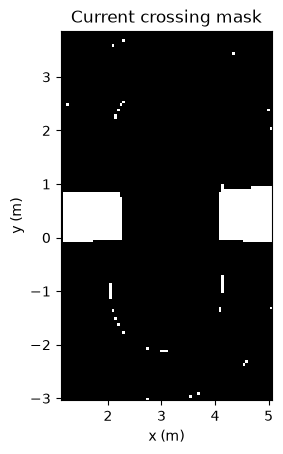

In [15]:
mc.build_crossing_mask(resolution=0.05)
mc.build_track_mask()

# Inspect the combined road mask.
mc.plot_crossing_mask("tracks")

# Remove roads from the drivable area to obtain crossing candidates.
mc.crossing_mask &= ~mc.track_mask
mc.plot_crossing_mask()

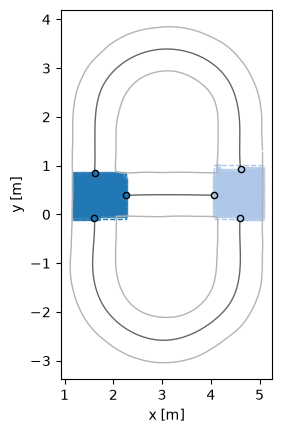

In [16]:
mc.identify_crossings()

mc.match_track_bounds_to_crossings(
    forward_distance=mc.track_width,
    backward_distance=mc.track_width / 4,
)

mc.plot_crossing_components()

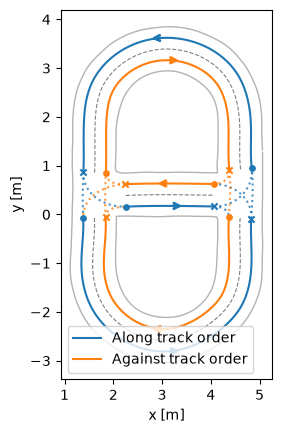

In [17]:
mc.create_lanes()
mc.connect_lanes()
mc.plot_lanes()

# The Algorithm

## What we have as a starting point
- A list of lane object that have
  - A list of points that parameterize the line from its start point to its end point
  - The orientation at the start and end point
  - A track segment index (to exclude start / end point pairs of the same track at a crossing to prohibit U-turns as valid successors)
  - A 'follows direction flag' used to determine start / end point directionality
  - Ids for the start and end crossing sections
  - A list of ids of next lanes (as valid successors)
  - A list of points that parametrize a cubic Bézier curve from the end point of the current lane to the valid successor lanes.

## What we additionally want (from the Lane objects)
- Add a line length parameter that is computed from the linear point distance sum of the parameterized line points
- A list of lengths of the linear point distance sum of the parameterized line points of the valid connections.

## What the algorithm should do
1. Take a start position and orientation (of the vehicle) and
2. Take a goal position (or a list of these)
3. Output the optimal path to reach this goal point or refuse if something is 'invalid'

## How we get there
1. Validate:
   1. Is the goal / all goals and the starting position inside the drivable area? For this, we can use masks / scipy.ndimage.
2. Check if the orientation of the starting pose matches with the orientation requirements. There is a scenario for both in a lane and on a crossing region where we cannot travel to the path / a new start point of a lane with the limits of the maximum steering angle.
3. If everything matches, determine the starting and stopping regions (Lane or crossing ids). Maybe actually do this before 2. as we need the information there already...
4. Find the shortest path from valid lane start points at this (or the next) crossing sections to the start point of the final lane / end point on the final crossing section. Here we just have to take care of the possibly different start / end conditions for lanes and crossings.
5. Concatenate path components to the final path
